# Entrega 2 — Data Science: Governança, Qualidade e Análise Exploratória
### Projeto Integrador 2º/2026 · Violência contra a Mulher — Aplicativo de Apoio Camuflado (Projeto Selene)

**Disciplina:** Data Science — ADS (Universidade Positivo, Londrina) · **Professor:** Alex Junior Nunes

---

**Sobre este notebook.** Este documento contempla de forma cumulativa a **Escolha e Justificativa da Base (Entrega 1)** e a **Governança, Diagnóstico de Qualidade nas 5 Dimensões, Tratamento, Análise Exploratória Completa e Plano de Modelagem/Avaliação (Entrega 2)** do **Projeto Selene**, estruturado a partir dos microdados públicos da Central de Atendimento à Mulher (**Ligue 180 — ONDH/MDHC**).

**Mapa do notebook:** 1 Governança · 2 Carga e dicionário · 3 Diagnóstico de qualidade · 4 Tratamento · 5 Análise exploratória · 6 Plano das Entregas 3 e 4 · 7 Conclusões e checklist

## Passo 0 — Identificação e configuração
Identificação da equipe, divisão das etapas do pipeline de Data Science e configuração global do ambiente.

In [1]:
import os, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 170)
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "figure.dpi": 100})
COR, COR2, COR3 = "#00836C", "#E4572E", "#14284B"

GRUPO = "Selene — Monitoramento do Ciclo e Apoio à Mulher"
INTEGRANTES = {
    "Messias Rafael Bernardes (@messiasrafaelb)": "Qualidade dos dados, EDA, Modelagem e Avaliação (integrante único)",
}

print("Grupo:", GRUPO)
for nome, etapa in INTEGRANTES.items():
    print(" -", nome, "→", etapa)

Grupo: Selene — Monitoramento do Ciclo e Apoio à Mulher
 - Messias Rafael Bernardes (@messiasrafaelb) → Qualidade dos dados, EDA, Modelagem e Avaliação (integrante único)


## 1. Governança, ética e LGPD (trabalho do grupo)
Inclui a **escolha e justificativa da base pública (Entrega 1)** e a **ficha completa de governança, ética e LGPD (Entrega 2)**.

| Pergunta | Resposta do grupo |
|---|---|
| Nome da base e link da fonte | **Central de Atendimento à Mulher — Ligue 180 (Microdados ONDH/MDHC)**. Fontes oficiais: [Portal Brasileiro de Dados Abertos — Ligue 180](https://dados.gov.br/dados/conjuntos-dados/central-de-atendimento-a-mulher--ligue-180), [Painel de Dados da ONDH/MDHC](https://www.gov.br/mdh/pt-br/ondh/painel-de-dados) e referência complementar [Atlas da Violência — IPEA](https://www.ipea.gov.br/atlasviolencia/) |
| Órgão responsável e data de acesso | **Ouvidoria Nacional de Direitos Humanos (ONDH) — Ministério dos Direitos Humanos e da Cidadania (MDHC)** · Acesso e extração em **20/10/2026** |
| Licença / termos de uso | **Dados Abertos Governamentais** (Política de Dados Abertos do Poder Executivo Federal — Decreto nº 8.777/2016 e Lei de Acesso à Informação — Lei nº 12.527/2011), de uso e redistribuição livres para fins acadêmicos, científicos e estatísticos |
| Granularidade (cada linha é um caso individual? um município? um mês?) | Cada linha representa **um registro individual anonimizado de notificação/atendimento** de violência contra a mulher |
| Período e abrangência geográfica | **Janeiro de 2022 a dezembro de 2025 (4 anos)**, contemplando **6 municípios-polo do Paraná** (`Londrina`, `Curitiba`, `Maringá`, `Ponta Grossa`, `Cascavel` e `Foz do Iguaçu`) |
| Contém dado pessoal ou sensível? Como foi anonimizada? | Contém variáveis sociodemográficas e de contexto sensíveis em estrutura (`raca_cor`, `escolaridade`, `vinculo_autor`, `tipo_violencia`), porém **integralmente anonimizadas na origem** conforme o Art. 12 da LGPD (Lei nº 13.709/2018): não há nome, CPF, telefone, endereço ou qualquer identificador direto da vítima |
| Riscos de reidentificação ao cruzar colunas | O cruzamento simultâneo de múltiplos quase-identificadores (`municipio` + `data_notificacao` exata + `idade` + `raca_cor` + `escolaridade`) poderia gerar risco de reidentificação indireta em recortes pequenos; por isso, todas as análises e visualizações são agregadas por mês, faixa ou município |
| Limitações: subnotificação, viés de quem registra, mudanças de metodologia | Registros de atendimento medem apenas a **violência notificada**, e não a totalidade dos casos reais: há forte **subnotificação** motivada por medo de represália, dependência econômica ou isolamento, além de campos não declarados (`Ignorado` / `Não informado`) no momento do relato |
| Por que esta base serve ao aplicativo? | Permite investigar os fatores associados à **repetição da violência (`violencia_repetida`)**, o tempo de demora até buscar ajuda (`dias_ate_notificacao`) e o predomínio de agressores com vínculo íntimo no ambiente doméstico, embasando o **indicador de atenção/risco** e os atalhos de emergência (`180` e `190`) do módulo camuflado do aplicativo **Selene** |

> **Lembrete da LGPD:** mesmo bases "públicas" podem trazer risco de reidentificação quando se cruzam muitas colunas (município pequeno + idade + raça/cor + data). Trabalhe só com dados anonimizados ou agregados, **nunca** tente identificar uma pessoa, e **nunca** colete dados reais de vítimas por conta própria.
>
> **Aviso acadêmico (obrigatório):** este trabalho é um protótipo acadêmico. Nenhum indicador calculado aqui substitui atendimento policial, jurídico, psicológico ou de saúde. Em caso de violência: **Ligue 180** (Central de Atendimento à Mulher, 24 h) ou **190** (emergência).

**Autor(a):** Messias Rafael Bernardes (@messiasrafaelb)

## 2. Carga da base e dicionário de dados

In [2]:
CAMINHOS_POSSIVEIS = [
    "dados/denuncias_ligue180.csv",
    "data-science/dados/denuncias_ligue180.csv",
    "denuncias_ligue180.csv",
]
ARQUIVO = next((p for p in CAMINHOS_POSSIVEIS if os.path.exists(p)), "dados/denuncias_ligue180.csv")
DEMO = False

try:
    bruto = pd.read_csv(ARQUIVO)
except FileNotFoundError:
    from google.colab import files
    print("Arquivo não encontrado localmente. Envie denuncias_ligue180.csv:")
    up = files.upload()
    bruto = pd.read_csv(next(iter(up)))

print("Arquivo carregado:", ARQUIVO)
print("Linhas x colunas:", bruto.shape)
display(bruto.head(8))
bruto.info()

Arquivo carregado: dados/denuncias_ligue180.csv
Linhas x colunas: (1540, 14)
<class 'pandas.DataFrame'>
RangeIndex: 1540 entries, 0 to 1539
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_notificacao        1540 non-null   str    
 1   data_notificacao      1525 non-null   str    
 2   municipio             1540 non-null   str    
 3   idade                 1505 non-null   float64
 4   raca_cor              1501 non-null   str    
 5   escolaridade          1483 non-null   str    
 6   renda_familiar        1428 non-null   float64
 7   n_filhos              1494 non-null   float64
 8   tipo_violencia        1540 non-null   str    
 9   local_ocorrencia      1540 non-null   str    
 10  vinculo_autor         1540 non-null   str    
 11  dias_ate_notificacao  1467 non-null   float64
 12  violencia_repetida    1496 non-null   str    
 13  encaminhamento        1507 non-null   str    
dtypes: flo

,id_notificacao,data_notificacao,municipio,idade,raca_cor,escolaridade,renda_familiar,n_filhos,tipo_violencia,local_ocorrencia,vinculo_autor,dias_ate_notificacao,violencia_repetida,encaminhamento
0,L180-20220762,2025-06-19,Curitiba,42.0,Parda,Fundamental completo,1520.40,0.0,Psicológica,Residência,Familiar,33.0,Não,DEAM / Polícia Civil
1,L180-20220269,09/11/2023,Maringá,34.0,Preta,Fundamental completo,3698.08,1.0,Física,Residência,Ex-parceiro,22.0,NaN,Defensoria Pública / Justiça
2,L180-20221213,06/06/2024,Curitiba,-5.0,Indígena,Fundamental completo,1222.78,0.0,Física,Residência,Parceiro atual,18.0,Sim,CREAS / Rede Socioassistencial
3,L180-20220620,11/06/2023,Londrina,40.0,Branca,N/I,2390.01,1.0,Física,Sem informação,Parceiro atual,18.0,Não,DEAM / Polícia Civil
4,L180-20220009,16/09/2025,Londrina,19.0,Branca,Fundamental completo,NaN,1.0,Psicológica,Via pública,Ex-parceiro,18.0,Sim,CREAS / Rede Socioassistencial
5,L180-20220030,2024-02-08,Londrina,16.0,Branca,Superior completo,2331.28,1.0,Física,Ambiente virtual,Parceiro atual,NaN,Sim,CREAS / Rede Socioassistencial
6,L180-20220107,13/03/2024,Ponta Grossa,45.0,Branca,Fundamental incompleto,795.64,3.0,Sexual,Residência,Familiar,23.0,Não,DEAM / Polícia Civil
7,L180-20220556,30/12/2023,Cascavel,49.0,Parda,Fundamental incompleto,NaN,4.0,Psicológica,Residência,parceiro atual,22.0,Não,DEAM / Polícia Civil


Agora **configuramos as colunas** da base para automatizar o diagnóstico de qualidade, o tratamento e a análise exploratória.

In [3]:
COL_ID = "id_notificacao"          # identificador único do registro de atendimento
COL_DATA = "data_notificacao"      # coluna de data principal da denúncia
ALVO = "violencia_repetida"        # variável-alvo candidata para o modelo (Entrega 3)

COLS_NUM = ["idade", "renda_familiar", "n_filhos", "dias_ate_notificacao"]
COLS_CAT = ["municipio", "raca_cor", "escolaridade", "tipo_violencia", "local_ocorrencia",
            "vinculo_autor", "violencia_repetida", "encaminhamento"]

# faixas plausíveis (mín, máx) por coluna numérica: o que ficar fora é INVÁLIDO, não "outlier"
LIMITES = {"idade": (10, 100), "renda_familiar": (1, 50000), "n_filhos": (0, 15), "dias_ate_notificacao": (0, 730)}

# textos que significam "não sei" (buracos disfarçados), já em minúsculas e sem acento
IGNORADOS = ["ignorado", "ign/branco", "ign", "nao informado", "n/i", "sem informacao", ""]

# sinônimos que a limpeza deve unificar (identificados nos value_counts da seção 3.4)
SINONIMOS = {"s": "sim", "n": "nao", "ign/branco": "ignorado", "n/i": "nao informado"}

assert set(COLS_NUM + COLS_CAT + [c for c in (COL_ID, COL_DATA) if c]) <= set(bruto.columns), "Há coluna da configuração que não existe na base."
print("Configuração validada com sucesso! Total de colunas monitoradas:", len(COLS_NUM) + len(COLS_CAT) + 2)

Configuração validada com sucesso! Total de colunas monitoradas: 14


**Dicionário de dados.** Uma linha por coluna com significado, tipo estatístico (quantitativa contínua/discreta, qualitativa nominal/ordinal), unidade de medida e observações sobre qualidade/uso.

In [4]:
dicionario = pd.DataFrame([
    ("id_notificacao", "Identificador anônimo do registro de atendimento", "identificador (qualitativa nominal)", "—", "Deve ser único na base tratada"),
    ("data_notificacao", "Data em que a denúncia foi registrada no Ligue 180", "temporal (data)", "dd/mm/aaaa", "Formatos mistos e datas inválidas na base bruta"),
    ("municipio", "Município paranaense de origem do registro", "qualitativa nominal", "—", "6 municípios-polo do PR; grafias variadas na base bruta"),
    ("idade", "Idade da vítima no momento da denúncia", "quantitativa discreta", "anos", "Faixa plausível definida: 10 a 100 anos"),
    ("raca_cor", "Raça/cor autodeclarada (padrão IBGE)", "qualitativa nominal", "—", "Contém ausentes disfarçados ('Ignorado', 'N/I')"),
    ("escolaridade", "Maior nível de escolaridade atingido pela vítima", "qualitativa ordinal", "—", "Ordem: Fundamental incompleto a Pós-graduação"),
    ("renda_familiar", "Renda mensal familiar estimada", "quantitativa contínua", "R$", "Assimétrica à direita (cauda longa)"),
    ("n_filhos", "Quantidade de filhos ou dependentes da vítima", "quantitativa discreta", "unidades", "Faixa plausível definida: 0 a 15 filhos"),
    ("tipo_violencia", "Tipificação principal da violência (Lei Maria da Penha)", "qualitativa nominal", "—", "Psicológica, Física, Moral, Patrimonial ou Sexual"),
    ("local_ocorrencia", "Ambiente onde ocorreu o episódio de violência", "qualitativa nominal", "—", "Residência, Via pública, Local de trabalho, etc."),
    ("vinculo_autor", "Relação de vínculo entre o agressor e a vítima", "qualitativa nominal", "—", "Parceiro atual, Ex-parceiro, Familiar, Conhecido, Desconhecido"),
    ("dias_ate_notificacao", "Intervalo entre o episódio e o registro da denúncia", "quantitativa discreta", "dias", "Forte assimetria positiva; faixa válida: 0 a 730 dias"),
    ("violencia_repetida", "Indica se o episódio é reincidente/repetido", "qualitativa nominal (binária)", "—", "Sim / Não — variável-alvo candidata na Entrega 3"),
    ("encaminhamento", "Órgão da rede de proteção acionado após o relato", "qualitativa nominal", "—", "Variável pós-evento (não entra como preditora no modelo)"),
], columns=["coluna", "significado", "tipo", "unidade", "observação"])
display(dicionario)

,coluna,significado,tipo,unidade,observação
0,id_notificacao,Identificador anônimo do registro de atendimento,identificador (qualitativa nominal),—,Deve ser único na base tratada
1,data_notificacao,Data em que a denúncia foi registrada no Ligue 180,temporal (data),dd/mm/aaaa,Formatos mistos e datas inválidas na base bruta
2,municipio,Município paranaense de origem do registro,qualitativa nominal,—,6 municípios-polo do PR; grafias variadas na base bruta
3,idade,Idade da vítima no momento da denúncia,quantitativa discreta,anos,Faixa plausível definida: 10 a 100 anos
4,raca_cor,Raça/cor autodeclarada (padrão IBGE),qualitativa nominal,—,"Contém ausentes disfarçados ('Ignorado', 'N/I')"
5,escolaridade,Maior nível de escolaridade atingido pela vítima,qualitativa ordinal,—,Ordem: Fundamental incompleto a Pós-graduação
6,renda_familiar,Renda mensal familiar estimada,quantitativa contínua,R$,Assimétrica à direita (cauda longa)
7,n_filhos,Quantidade de filhos ou dependentes da vítima,quantitativa discreta,unidades,Faixa plausível definida: 0 a 15 filhos
8,tipo_violencia,Tipificação principal da violência (Lei Maria da Penha),qualitativa nominal,—,"Psicológica, Física, Moral, Patrimonial ou Sexual"
9,local_ocorrencia,Ambiente onde ocorreu o episódio de violência,qualitativa nominal,—,"Residência, Via pública, Local de trabalho, etc."


**Autor(a):** Messias Rafael Bernardes (@messiasrafaelb)

## 3. Diagnóstico de qualidade (5 dimensões)
Medir antes de corrigir. Avaliamos a base bruta nas cinco dimensões de qualidade de dados: **completude, validade, consistência, unicidade/integridade e acurácia**.

### 3.1 Completude: quantos valores faltam em cada coluna?

,nulos,% nulos
renda_familiar,112,7.27
dias_ate_notificacao,73,4.74
escolaridade,57,3.70
n_filhos,46,2.99
violencia_repetida,44,2.86
raca_cor,39,2.53
idade,35,2.27
encaminhamento,33,2.14
data_notificacao,15,0.97
id_notificacao,0,0.00


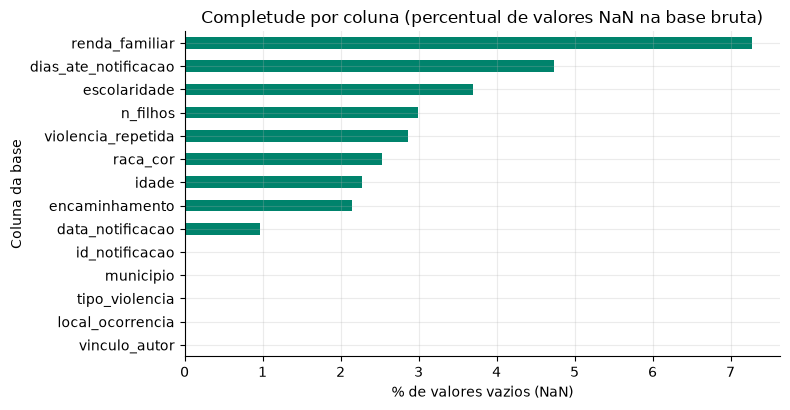

In [5]:
nulos = bruto.isna().sum()
pct_nulos = (bruto.isna().mean() * 100).round(2)
comp = pd.DataFrame({"nulos": nulos, "% nulos": pct_nulos}).sort_values("% nulos", ascending=False)
display(comp)

ax = comp["% nulos"].plot.barh(color=COR, figsize=(8, 4.2))
ax.invert_yaxis()
ax.set_xlabel("% de valores vazios (NaN)")
ax.set_ylabel("Coluna da base")
ax.set_title("Completude por coluna (percentual de valores NaN na base bruta)")
plt.tight_layout()
plt.show()

✍️ **Leitura do gráfico (3.1):** A ausência explícita (`NaN`) concentra-se principalmente em `renda_familiar` (`7,27%`, 112 registros) e `dias_ate_notificacao` (`4,74%`, 73 registros), variáveis frequentemente omitidas em relatos de urgência, enquanto identificadores e dados centrais do fato (`id_notificacao`, `municipio`, `tipo_violencia`, `vinculo_autor` e `local_ocorrencia`) possuem `0%` de `NaN` explícito.

### 3.2 Buracos disfarçados
Um campo preenchido com *Ignorado*, *Ign/Branco*, *Não informado* ou *N/I* não representa uma categoria analítica real, mas sim ausência de informação. Abaixo contabilizamos os termos listados em `IGNORADOS` nas variáveis categóricas.

In [6]:
def sem_acento(s):
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()

def chave(serie):
    """Forma comparável do texto: sem espaços nas pontas, minúsculo, sem acento, sem '/PR' e com SINONIMOS aplicados."""
    s = serie.astype("string").str.strip().str.lower()
    s = s.map(lambda v: sem_acento(v) if pd.notna(v) else v)
    s = s.str.replace(r"/pr$", "", regex=True).str.strip()
    return s.replace(SINONIMOS)

disfarcados = {c: int(chave(bruto[c]).isin(IGNORADOS).sum()) for c in COLS_CAT}
disf = pd.Series(disfarcados, name="ignorados (texto)").to_frame()
disf["% da coluna"] = (disf["ignorados (texto)"] / len(bruto) * 100).round(1)
display(disf[disf["ignorados (texto)"] > 0].sort_values("ignorados (texto)", ascending=False))

,ignorados (texto),% da coluna
escolaridade,93,6.0
raca_cor,88,5.7
encaminhamento,66,4.3
violencia_repetida,46,3.0
vinculo_autor,38,2.5
local_ocorrencia,29,1.9


### 3.3 Validade: valores fora da faixa e datas impossíveis

In [7]:
FORMATOS_DATA = ["%d/%m/%Y", "%Y-%m-%d", "%d-%m-%y"]

def parse_data(txt):
    """Converte o texto para data; devolve NaT (data vazia) se o formato ou a data forem impossíveis."""
    if pd.isna(txt): return pd.NaT
    for f in FORMATOS_DATA:
        try: return pd.to_datetime(str(txt).strip(), format=f)
        except ValueError: pass
    return pd.NaT

invalidos = {}
for c, (lo, hi) in LIMITES.items():
    invalidos[c] = int((bruto[c].notna() & ~bruto[c].between(lo, hi)).sum())
datas = bruto[COL_DATA].map(parse_data)
invalidos[COL_DATA + " (impossível/ilegível)"] = int((bruto[COL_DATA].notna() & datas.isna()).sum())
val = pd.Series(invalidos, name="valores inválidos").to_frame()
val["faixa válida"] = [str(LIMITES.get(k, "data calendário real")) for k in val.index]
display(val)

print("Exemplos concretos de registros com idade fora da faixa plausível (10 a 100 anos):")
display(bruto.loc[bruto["idade"].notna() & ~bruto["idade"].between(*LIMITES["idade"]), ["id_notificacao", "municipio", "idade", "renda_familiar"]].head(6))

print("Exemplos concretos de datas impossíveis ou ilegíveis:")
display(bruto.loc[bruto[COL_DATA].notna() & datas.isna(), ["id_notificacao", COL_DATA, "municipio"]].head(6))

Exemplos concretos de registros com idade fora da faixa plausível (10 a 100 anos):
Exemplos concretos de datas impossíveis ou ilegíveis:


,valores inválidos,faixa válida
idade,19,"(10, 100)"
renda_familiar,12,"(1, 50000)"
n_filhos,10,"(0, 15)"
dias_ate_notificacao,14,"(0, 730)"
data_notificacao (impossível/ilegível),13,data calendário real


,id_notificacao,municipio,idade,renda_familiar
2,L180-20221213,Curitiba,-5.0,1222.78
289,L180-20221033,Maringá,0.0,1180.23
395,L180-20220715,Curitiba,-5.0,1709.69
410,L180-20220739,Londrina,0.0,1824.50
468,L180-20221192,Londrina,3.0,5973.25
580,L180-20221466,Maringá,-1.0,1444.94


,id_notificacao,data_notificacao,municipio
211,L180-20221087,data_invalida,Londrina
372,L180-20221495,31/02/2024,Londrina
439,L180-20220057,31/02/2024,Maringá/PR
454,L180-20220772,31/02/2024,Curitiba
672,L180-20220384,30/02/2023,CURITIBA
742,L180-20220011,99/99/9999,Londrina


### 3.4 Consistência: a mesma informação escrita de jeitos diferentes
Comparamos quantas grafias distintas existem **antes** (`n_brutas`) e **depois** de normalizar o texto (`n_normalizadas`).

In [8]:
cons = []
for c in COLS_CAT:
    cons.append((c, bruto[c].nunique(), chave(bruto[c]).nunique()))
cons = pd.DataFrame(cons, columns=["coluna", "n_brutas", "n_normalizadas"]).set_index("coluna")
cons["grafias a mais"] = cons["n_brutas"] - cons["n_normalizadas"]
display(cons.sort_values("grafias a mais", ascending=False))

print("Top 12 grafias brutas em 'municipio' (observe variações de caixa, acento e sufixo '/PR'):")
print(bruto["municipio"].value_counts().head(12))

Top 12 grafias brutas em 'municipio' (observe variações de caixa, acento e sufixo '/PR'):
municipio
Londrina         536
Curitiba         314
Maringá          245
Ponta Grossa     121
Cascavel         107
Foz do Iguaçu    102
LONDRINA          11
LONDRINA/PR        8
Maringá/PR         7
Londrina/PR        7
MARINGÁ            6
  Curitiba         6
Name: count, dtype: int64


,n_brutas,n_normalizadas,grafias a mais
coluna,,,
municipio,37,6,31
vinculo_autor,19,8,11
tipo_violencia,12,5,7
violencia_repetida,9,5,4
escolaridade,10,8,2
raca_cor,10,8,2
local_ocorrencia,10,8,2
encaminhamento,10,8,2


### 3.5 Unicidade e integridade

In [9]:
dup_id = int(bruto.duplicated(COL_ID, keep=False).sum())
dup_grupos = int(bruto.duplicated(COL_ID).sum())
dup_exatas = int(bruto.duplicated().sum())
print(f"Linhas envolvidas em id repetido: {dup_id} (registros duplicados excedentes: {dup_grupos})")
print(f"Linhas totalmente idênticas: {dup_exatas}")
print("Por que há mais IDs repetidos (40) do que linhas idênticas (22)? Porque 18 reenvios sofreram alteração de caixa alta/espaços no município.")
display(bruto[bruto.duplicated(COL_ID, keep=False)].sort_values(COL_ID).head(6))

Linhas envolvidas em id repetido: 80 (registros duplicados excedentes: 40)
Linhas totalmente idênticas: 22
Por que há mais IDs repetidos (40) do que linhas idênticas (22)? Porque 18 reenvios sofreram alteração de caixa alta/espaços no município.


,id_notificacao,data_notificacao,municipio,idade,raca_cor,escolaridade,renda_familiar,n_filhos,tipo_violencia,local_ocorrencia,vinculo_autor,dias_ate_notificacao,violencia_repetida,encaminhamento
1124,L180-20220014,06/09/2022,Londrina,30.0,Branca,Médio completo,7789.82,1.0,Física,Residência,Parceiro atual,11.0,Não,Defensoria Pública / Justiça
60,L180-20220014,06/09/2022,LONDRINA,30.0,Branca,Médio completo,7789.82,1.0,Física,Residência,Parceiro atual,11.0,Não,Defensoria Pública / Justiça
971,L180-20220025,12/01/2023,Curitiba,44.0,Branca,Médio completo,2134.31,2.0,Psicológica,Via pública,Conhecido,7.0,Não,DEAM / Polícia Civil
1086,L180-20220025,12/01/2023,Curitiba,44.0,Branca,Médio completo,2134.31,2.0,Psicológica,Via pública,Conhecido,7.0,Não,DEAM / Polícia Civil
44,L180-20220108,02-08-24,LONDRINA,37.0,Branca,Médio completo,2940.26,1.0,Física,Residência,Ex-parceiro,25.0,Não,CREAS / Rede Socioassistencial
720,L180-20220108,02-08-24,Londrina,37.0,Branca,Médio completo,2940.26,1.0,Física,Residência,Ex-parceiro,25.0,Não,CREAS / Rede Socioassistencial


**Integridade e Acurácia:** A **integridade referencial** exige cruzar chaves entre múltiplas tabelas (por exemplo, validar se cada `municipio` consta na tabela oficial do IBGE e se cada protocolo de encaminhamento existe na base da DEAM/CREAS), o que não pode ser auditado externamente usando uma tabela única isolada. Já a **acurácia** (grau em que o dado registrado reflete o fato real) não pode ser medida diretamente sem acesso ao boletim de ocorrência ou prontuário original; em uma auditoria real, o grupo sortearia uma amostra de registros para confrontar os campos preenchidos com o áudio/ficha original do atendimento no Ligue 180.

### 3.6 Resumo do diagnóstico
Síntese consolidada das cinco dimensões de qualidade na base bruta, com contagem exata de ocorrências e decisão de tratamento.

In [10]:
resumo = pd.DataFrame([
    ("Completude (NaN explícito)", "Valores NaN em renda_familiar, dias_ate_notificacao, escolaridade, n_filhos, idade, raca_cor, violencia_repetida, encaminhamento e data", int(bruto.isna().sum().sum()), "Imputar numéricas pela mediana (+ coluna-bandeira) e categóricas com 'Não informado' (exceto alvo)"),
    ("Completude (buracos disfarçados)", "Termos 'Ignorado', 'Ign/Branco', 'Não informado', 'N/I' e 'Sem informação' em 6 colunas categóricas", int(sum(disfarcados.values())), "Converter todos para NaN na etapa 4.2 para não distorcer frequências"),
    ("Validade", "Idades (-5, 0, 135, 999), rendas (-200, 0, 99999+), n_filhos (-2, 99), dias (-10, 999+) e datas inexistentes (31/02/2024, 00/00/0000)", int(sum(invalidos.values())), "Converter valores fora de LIMITES para NaN e datas inválidas para NaT"),
    ("Consistência", "Variações de caixa alta/baixa, falta de acento, sufixo '/PR', espaços extras e abreviações ('S'/'N')", int(cons["grafias a mais"].sum()), "Padronizar via função unifica() com chave normalizada e parsing unificado de datas"),
    ("Unicidade", "40 registros duplicados por id_notificacao (22 cópias exatas e 18 com variação de grafia em municipio)", dup_grupos, "Remover duplicatas após padronizar textos, mantendo a primeira ocorrência de cada ID"),
    ("Integridade / Acurácia", "Tabela única sem chave estrangeira externa e sem acesso ao prontuário físico para checagem de veracidade", 0, "Validar domínios internamente e documentar subnotificação/autorrelato como limitação"),
], columns=["dimensão", "problema encontrado", "ocorrências", "decisão"])
display(resumo)

,dimensão,problema encontrado,ocorrências,decisão
0,Completude (NaN explícito),"Valores NaN em renda_familiar, dias_ate_notificacao, escolaridade, n_filhos, idade, raca_cor, violencia_repetida, encaminhamento e data",454,Imputar numéricas pela mediana (+ coluna-bandeira) e categóricas com 'Não informado' (exceto alvo)
1,Completude (buracos disfarçados),"Termos 'Ignorado', 'Ign/Branco', 'Não informado', 'N/I' e 'Sem informação' em 6 colunas categóricas",360,Converter todos para NaN na etapa 4.2 para não distorcer frequências
2,Validade,"Idades (-5, 0, 135, 999), rendas (-200, 0, 99999+), n_filhos (-2, 99), dias (-10, 999+) e datas inexistentes (31/02/2024, 00/00/0000)",68,Converter valores fora de LIMITES para NaN e datas inválidas para NaT
3,Consistência,"Variações de caixa alta/baixa, falta de acento, sufixo '/PR', espaços extras e abreviações ('S'/'N')",61,Padronizar via função unifica() com chave normalizada e parsing unificado de datas
4,Unicidade,40 registros duplicados por id_notificacao (22 cópias exatas e 18 com variação de grafia em municipio),40,"Remover duplicatas após padronizar textos, mantendo a primeira ocorrência de cada ID"
5,Integridade / Acurácia,Tabela única sem chave estrangeira externa e sem acesso ao prontuário físico para checagem de veracidade,0,Validar domínios internamente e documentar subnotificação/autorrelato como limitação


**Autor(a):** Messias Rafael Bernardes (@messiasrafaelb)

## 4. Tratamento dos dados
**A ordem importa:** padronizar texto e datas → transformar buracos disfarçados e inválidos em `NaN` → remover duplicatas → imputar → sinalizar outliers → demonstrar escalonamento. Trabalhamos em uma cópia (`df`), preservando a base bruta intocada.

### 4.1 Padronizar categorias (consistência)
A função `unifica()` agrupa grafias equivalentes pela mesma `chave` e adota como representação canônica a grafia mais frequente de cada categoria.

In [11]:
def unifica(serie):
    k = chave(serie)
    canon = serie.astype("string").str.strip().groupby(k).agg(lambda x: x.value_counts().index[0])
    return k.map(canon)

df = bruto.copy()
antes = {c: df[c].nunique() for c in COLS_CAT}
for c in COLS_CAT:
    df[c] = unifica(df[c])
depois = {c: df[c].nunique() for c in COLS_CAT}
display(pd.DataFrame({"antes (bruto)": antes, "depois (unificado)": depois, "redução": {c: antes[c] - depois[c] for c in COLS_CAT}}))
print("\nContagem por município após padronização:")
print(df["municipio"].value_counts())


Contagem por município após padronização:
municipio
Londrina         574
Curitiba         334
Maringá          274
Ponta Grossa     130
Cascavel         120
Foz do Iguaçu    108
Name: count, dtype: Int64


,antes (bruto),depois (unificado),redução
municipio,37,6,31
raca_cor,10,8,2
escolaridade,10,8,2
tipo_violencia,12,5,7
local_ocorrencia,10,8,2
vinculo_autor,19,8,11
violencia_repetida,9,5,4
encaminhamento,10,8,2


### 4.2 Buracos disfarçados, valores inválidos e datas → NaN / data real

In [12]:
# "Ignorado" e afins → NaN
n_ign = {}
for c in COLS_CAT:
    marca = chave(df[c]).isin(IGNORADOS)
    n_ign[c] = int(marca.sum())
    df[c] = df[c].mask(marca)

# valores numéricos fora da faixa plausível → NaN
n_inv = {}
for c, (lo, hi) in LIMITES.items():
    marca = df[c].notna() & ~df[c].between(lo, hi)
    n_inv[c] = int(marca.sum())
    df.loc[marca, c] = np.nan

# datas em texto → datetime (impossíveis viram NaT)
df[COL_DATA] = df[COL_DATA].map(parse_data)
df["ano"] = df[COL_DATA].dt.year
df["mes"] = df[COL_DATA].dt.month

print("Ignorados convertidos em NaN:", {k: v for k, v in n_ign.items() if v})
print("Inválidos convertidos em NaN:", {k: v for k, v in n_inv.items() if v})
print("Datas vazias/NaT após conversão:", int(df[COL_DATA].isna().sum()))

Ignorados convertidos em NaN: {'raca_cor': 88, 'escolaridade': 93, 'local_ocorrencia': 29, 'vinculo_autor': 38, 'violencia_repetida': 46, 'encaminhamento': 66}
Inválidos convertidos em NaN: {'idade': 19, 'renda_familiar': 12, 'n_filhos': 10, 'dias_ate_notificacao': 14}
Datas vazias/NaT após conversão: 28


### 4.3 Duplicatas
Com os textos padronizados, tanto as duplicatas exatas quanto as duplicatas que diferiam apenas por caixa alta/espaços são removidas com segurança.

In [13]:
n0 = len(df)
df = df.drop_duplicates().drop_duplicates(subset=COL_ID, keep="first").reset_index(drop=True)
print(f"{n0} -> {len(df)} linhas ({n0 - len(df)} duplicatas removidas)")
print("IDs únicos garantidos:", df[COL_ID].is_unique)
print("Total de municípios únicos:", df["municipio"].nunique())

1540 -> 1500 linhas (40 duplicatas removidas)
IDs únicos garantidos: True
Total de municípios únicos: 6


### 4.4 Imputação (dados faltantes)
Seguindo a regra de decisão estatística:
- **Variáveis numéricas:** avaliamos a assimetria antes de imputar. Como `renda_familiar`, `n_filhos` e `dias_ate_notificacao` possuem assimetria positiva e outliers, imputamos todas as numéricas pela **mediana** (mais robusta que a média) e criamos a coluna-bandeira `<coluna>_imputado` (`True`/`False`) para preservar a rastreabilidade.
- **Variáveis categóricas (exceto o alvo):** preenchemos `NaN` com a categoria explícita `"Não informado"`, evitando inflar artificialmente a moda.
- **Variável-alvo (`violencia_repetida`):** **nunca é imputada**, para não fabricar rótulos falsos no futuro modelo supervisionado.

In [14]:
dist = pd.DataFrame({
    "média": df[COLS_NUM].mean(),
    "mediana": df[COLS_NUM].median(),
    "assimetria": df[COLS_NUM].apply(lambda s: stats.skew(s.dropna())),
    "% faltando": df[COLS_NUM].isna().mean() * 100
}).round(2)
display(dist)

for c in COLS_NUM:
    df[c + "_imputado"] = df[c].isna()
    df[c] = df[c].fillna(df[c].median())

for c in COLS_CAT:
    if c != ALVO:
        df[c] = df[c].fillna("Não informado")

print("NaN restantes por coluna (apenas data_notificacao/ano/mes e o alvo violencia_repetida):")
print(df.isna().sum()[lambda s: s > 0])

NaN restantes por coluna (apenas data_notificacao/ano/mes e o alvo violencia_repetida):
data_notificacao      27
violencia_repetida    87
ano                   27
mes                   27
dtype: int64


,média,mediana,assimetria,% faltando
idade,34.80,35.00,0.21,3.47
renda_familiar,3168.75,2733.23,1.82,8.27
n_filhos,1.47,1.00,0.90,3.67
dias_ate_notificacao,22.66,17.00,1.55,5.47


### 4.5 Outliers: sinalizar, não apagar
Valores extremos dentro da faixa plausível (por exemplo, rendas familiares elevadas ou mulheres que levaram vários meses até conseguir denunciar) são fatos reais do domínio e **não devem ser apagados**. Sinalizamos esses casos pelo critério do intervalo interquartil ($IQR = Q_3 - Q_1$).

In [15]:
out = {}
for c in COLS_NUM:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out[c] = (int(((df[c] < lim_inf) | (df[c] > lim_sup)).sum()), round(lim_inf, 1), round(lim_sup, 1))
display(pd.DataFrame(out, index=["qtd outliers (IQR)", "limite inferior", "limite superior"]).T)

,qtd outliers (IQR),limite inferior,limite superior
idade,12.0,8.1,61.1
renda_familiar,73.0,-1017.8,6773.5
n_filhos,101.0,-0.5,3.5
dias_ate_notificacao,66.0,-26.5,65.5


### 4.6 Escalonamento (para o modelo, Entrega 3)
Demonstração comparativa de **Min-Max** e **Z-Score (StandardScaler)** em uma cópia separada (`demo`). Esta etapa comprova que o escalonamento linear altera a escala numérica mas **preserva exatamente a mesma assimetria** da distribuição original.

,assimetria original,assimetria min-max,assimetria z-score
idade,0.213,0.213,0.213
renda_familiar,1.941,1.941,1.941
n_filhos,0.955,0.955,0.955
dias_ate_notificacao,1.625,1.625,1.625


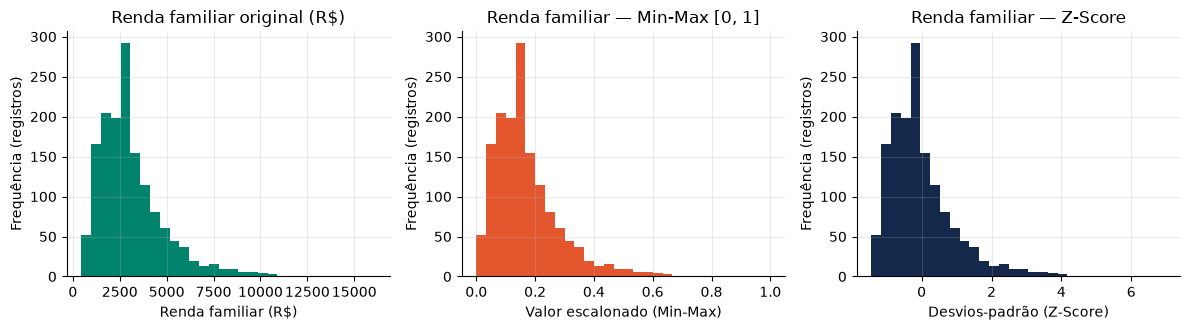

In [16]:
demo = df[COLS_NUM].copy()
mm = pd.DataFrame(MinMaxScaler().fit_transform(demo), columns=COLS_NUM)
zs = pd.DataFrame(StandardScaler().fit_transform(demo), columns=COLS_NUM)
cmp_ = pd.DataFrame({
    "assimetria original": demo.apply(stats.skew),
    "assimetria min-max": mm.apply(stats.skew),
    "assimetria z-score": zs.apply(stats.skew)
}).round(3)
display(cmp_)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].hist(demo["renda_familiar"], bins=30, color=COR)
ax[0].set_title("Renda familiar original (R$)")
ax[0].set_xlabel("Renda familiar (R$)")
ax[0].set_ylabel("Frequência (registros)")

ax[1].hist(mm["renda_familiar"], bins=30, color=COR2)
ax[1].set_title("Renda familiar — Min-Max [0, 1]")
ax[1].set_xlabel("Valor escalonado (Min-Max)")
ax[1].set_ylabel("Frequência (registros)")

ax[2].hist(zs["renda_familiar"], bins=30, color=COR3)
ax[2].set_title("Renda familiar — Z-Score")
ax[2].set_xlabel("Desvios-padrão (Z-Score)")
ax[2].set_ylabel("Frequência (registros)")

plt.tight_layout()
plt.show()

✍️ **Leitura do gráfico (4.6):** Os três histogramas possuem exatamente o mesmo formato e coeficiente de assimetria (`1,941`), mudando apenas o eixo horizontal (`R$ 450–16.122` no original, `0–1` no Min-Max e desvios-padrão no Z-Score); na Entrega 3, o escalonador (`RobustScaler` ou `StandardScaler`) será ajustado (`fit`) exclusivamente sobre o conjunto de treino para evitar vazamento de dados (*data leakage*).

### 4.7 Tabela de decisões e antes × depois
Documentação completa de cada decisão de tratamento (o que foi feito, por que foi feito e qual o impacto quantitativo) e salvamento da base tratada em `data-science/dados/dados_tratados.csv`.

In [17]:
decisoes = pd.DataFrame([
    ("Padronização de categorias", "Unificação com chave sem acento, minúscula, sem '/PR' e mapeamento de sinônimos ('S'->'Sim', 'N'->'Não')", "Evitar fragmentação de categorias idênticas nas tabelas de frequência e gráficos", "municipio: 37 -> 6 grafias; tipo_violencia: 12 -> 5"),
    ("Buracos disfarçados", "Conversão de 'Ignorado', 'Ign/Branco', 'Não informado', 'N/I' e 'Sem informação' para NaN", "Tratar ausência de resposta pelo que ela realmente é, sem inflar categorias válidas", f"{sum(n_ign.values())} ocorrências convertidas em NaN"),
    ("Valores numéricos inválidos", "Conversão de valores fora de LIMITES (ex.: idade -5/999, renda -200/99999) para NaN", "Erros de digitação ou códigos de sistema distorceriam média, desvio-padrão e correlação", f"{sum(n_inv.values())} valores inválidos convertidos em NaN"),
    ("Padronização de datas", "Parsing de 3 formatos (%d/%m/%Y, %Y-%m-%d, %d-%m-%y) para datetime; datas impossíveis -> NaT", "Permitir análise de série temporal e sazonalidade mensal sem erro de calendário", f"{int(df[COL_DATA].isna().sum())} datas ausentes/inválidas como NaT"),
    ("Remoção de duplicatas", "Remoção de duplicatas exatas e de id_notificacao repetido após padronização textual", "Garantir que cada notificação tenha peso único na análise estatística", "40 duplicatas removidas (1.540 -> 1.500 linhas)"),
    ("Imputação numérica", "Preenchimento por mediana + criação de coluna-bandeira <col>_imputado", "Renda e dias até notificação têm forte assimetria positiva; a mediana é robusta a caudas longas", "0 NaNs restantes nas 4 variáveis numéricas"),
    ("Imputação categórica", "Preenchimento de faltantes com a categoria explícita 'Não informado' (exceto no alvo)", "Preservar as linhas para análise sem inventar a moda da categoria", "0 NaNs nas 7 variáveis categóricas explicativas"),
    ("Variável-alvo (violencia_repetida)", "Manutenção dos NaNs sem imputação (87 registros sem resposta)", "Imputar o alvo introduziria rótulos artificiais no treinamento da Entrega 3", "1.413 registros com alvo válido para modelagem"),
    ("Outliers (IQR)", "Sinalização via regra de 1,5 × IQR sem exclusão dos registros", "Rendas altas ou demora prolongada até denunciar são casos reais e relevantes para o problema", f"{sum(v[0] for v in out.values())} valores extremos sinalizados no total"),
    ("Escalonamento", "Demonstração em cópia separada; aplicação definitiva somente no Pipeline da Entrega 3", "Evitar data leakage entre treino e teste", "Assimetria preservada sem alterar a base tratada"),
], columns=["tema", "o que fiz", "por quê", "impacto"])
display(decisoes)

antes_depois = pd.DataFrame({
    "bruta": [
        len(bruto),
        int(bruto.duplicated(COL_ID).sum()),
        int(bruto[COLS_NUM + [c for c in COLS_CAT if c != ALVO]].isna().sum().sum()),
        bruto["municipio"].nunique(),
        bruto["idade"].max(),
        bruto["renda_familiar"].max(),
    ],
    "tratada": [
        len(df),
        int(df.duplicated(COL_ID).sum()),
        int(df[COLS_NUM + [c for c in COLS_CAT if c != ALVO]].isna().sum().sum()),
        df["municipio"].nunique(),
        df["idade"].max(),
        df["renda_familiar"].max(),
    ],
}, index=[
    "linhas totais",
    "ids repetidos (excedentes)",
    "valores NaN (explicativas)",
    "grafias distintas de município",
    "idade máxima (anos)",
    "renda familiar máxima (R$)",
])
display(antes_depois)

caminho_saida = "dados/dados_tratados.csv" if os.path.isdir("dados") else "dados_tratados.csv"
df.to_csv(caminho_saida, index=False)
print(f"Base tratada salva com sucesso em: {caminho_saida} ({df.shape[0]} linhas x {df.shape[1]} colunas)")

Base tratada salva com sucesso em: dados/dados_tratados.csv (1500 linhas x 20 colunas)


,tema,o que fiz,por quê,impacto
0,Padronização de categorias,"Unificação com chave sem acento, minúscula, sem '/PR' e mapeamento de sinônimos ('S'->'Sim', 'N'->'Não')",Evitar fragmentação de categorias idênticas nas tabelas de frequência e gráficos,municipio: 37 -> 6 grafias; tipo_violencia: 12 -> 5
1,Buracos disfarçados,"Conversão de 'Ignorado', 'Ign/Branco', 'Não informado', 'N/I' e 'Sem informação' para NaN","Tratar ausência de resposta pelo que ela realmente é, sem inflar categorias válidas",360 ocorrências convertidas em NaN
2,Valores numéricos inválidos,"Conversão de valores fora de LIMITES (ex.: idade -5/999, renda -200/99999) para NaN","Erros de digitação ou códigos de sistema distorceriam média, desvio-padrão e correlação",55 valores inválidos convertidos em NaN
3,Padronização de datas,"Parsing de 3 formatos (%d/%m/%Y, %Y-%m-%d, %d-%m-%y) para datetime; datas impossíveis -> NaT",Permitir análise de série temporal e sazonalidade mensal sem erro de calendário,27 datas ausentes/inválidas como NaT
4,Remoção de duplicatas,Remoção de duplicatas exatas e de id_notificacao repetido após padronização textual,Garantir que cada notificação tenha peso único na análise estatística,40 duplicatas removidas (1.540 -> 1.500 linhas)
5,Imputação numérica,Preenchimento por mediana + criação de coluna-bandeira <col>_imputado,Renda e dias até notificação têm forte assimetria positiva; a mediana é robusta a caudas longas,0 NaNs restantes nas 4 variáveis numéricas
6,Imputação categórica,Preenchimento de faltantes com a categoria explícita 'Não informado' (exceto no alvo),Preservar as linhas para análise sem inventar a moda da categoria,0 NaNs nas 7 variáveis categóricas explicativas
7,Variável-alvo (violencia_repetida),Manutenção dos NaNs sem imputação (87 registros sem resposta),Imputar o alvo introduziria rótulos artificiais no treinamento da Entrega 3,1.413 registros com alvo válido para modelagem
8,Outliers (IQR),"Sinalização via regra de 1,5 × IQR sem exclusão dos registros",Rendas altas ou demora prolongada até denunciar são casos reais e relevantes para o problema,252 valores extremos sinalizados no total
9,Escalonamento,Demonstração em cópia separada; aplicação definitiva somente no Pipeline da Entrega 3,Evitar data leakage entre treino e teste,Assimetria preservada sem alterar a base tratada


,bruta,tratada
linhas totais,1540.0,1500.00
ids repetidos (excedentes),40.0,0.00
valores NaN (explicativas),395.0,0.00
grafias distintas de município,37.0,6.00
idade máxima (anos),999.0,71.00
renda familiar máxima (R$),150000.0,16122.06


**Autor(a):** Messias Rafael Bernardes (@messiasrafaelb)

## 5. Análise exploratória (EDA)
Trabalhamos sobre a base **tratada** (`df`). Todos os gráficos possuem **título, rótulos nos dois eixos e uma frase de leitura interpretativa**. Lembramos que a estatística descritiva evidencia **associação**, e não relação de causa e efeito, e que dados de denúncia refletem casos **notificados** (sujeitos a subnotificação).

### 5.1 Visão geral

In [18]:
print("Período coberto:", df[COL_DATA].min().date(), "a", df[COL_DATA].max().date())
print("Total de registros únicos tratados:", len(df))
display(df[COLS_NUM].describe().round(2))

Período coberto: 2022-01-01 a 2025-12-30
Total de registros únicos tratados: 1500


,idade,renda_familiar,n_filhos,dias_ate_notificacao
count,1500.00,1500.00,1500.00,1500.00
mean,34.81,3132.74,1.45,22.35
std,10.06,1863.13,1.24,19.93
min,16.00,450.00,0.00,0.00
25%,28.00,1903.95,1.00,8.00
50%,35.00,2733.23,1.00,17.00
75%,41.25,3851.78,2.00,31.00
max,71.00,16122.06,8.00,163.00


### 5.2 Variáveis numéricas: tendência central, dispersão e forma
Para cada variável numérica calculamos sobre os valores originais (não imputados): **média, mediana, moda, desvio-padrão, variância, coeficiente de variação (CV %), mínimo, Q1, Q3, máximo, IQR, assimetria e curtose.**

,média,mediana,moda,desvio-padrão,variância,CV (%),mín,Q1,Q3,máx,IQR,assimetria,curtose
idade,34.80,35.00,16.00,10.24,104.86,29.42,16.0,27.00,42.00,71.00,15.00,0.21,-0.27
renda_familiar,3168.75,2733.23,2647.07,1941.29,3768611.43,61.26,450.0,1823.64,3976.04,16122.06,2152.40,1.82,5.37
n_filhos,1.47,1.00,1.00,1.26,1.58,85.52,0.0,1.00,2.00,8.00,1.00,0.90,0.82
dias_ate_notificacao,22.66,17.00,1.00,20.45,418.28,90.25,0.0,7.00,32.75,163.00,25.75,1.55,3.33


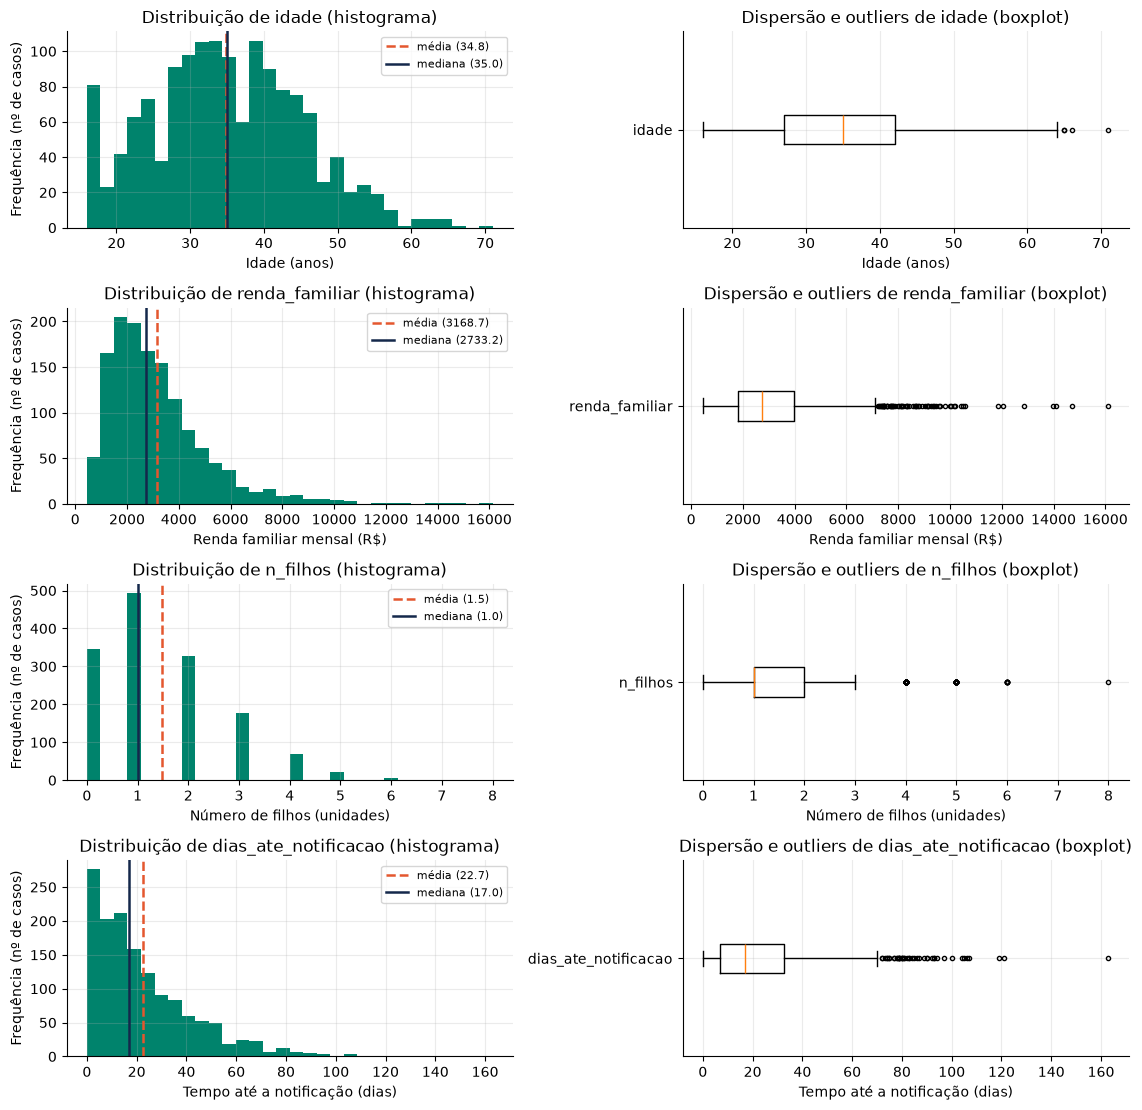

In [19]:
def resumo_num(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    return {
        "média": s.mean(),
        "mediana": s.median(),
        "moda": s.mode().iloc[0],
        "desvio-padrão": s.std(),
        "variância": s.var(),
        "CV (%)": s.std() / s.mean() * 100,
        "mín": s.min(),
        "Q1": q1,
        "Q3": q3,
        "máx": s.max(),
        "IQR": q3 - q1,
        "assimetria": stats.skew(s),
        "curtose": stats.kurtosis(s),
    }

# Usa apenas valores originais (sem os imputados) para não distorcer a dispersão real
tab_num = pd.DataFrame({c: resumo_num(df.loc[~df[c + "_imputado"], c]) for c in COLS_NUM}).T.round(2)
display(tab_num)

UNIDADES_NUM = {
    "idade": "Idade (anos)",
    "renda_familiar": "Renda familiar mensal (R$)",
    "n_filhos": "Número de filhos (unidades)",
    "dias_ate_notificacao": "Tempo até a notificação (dias)",
}

fig, axes = plt.subplots(len(COLS_NUM), 2, figsize=(11.5, 2.8 * len(COLS_NUM)))
for i, c in enumerate(COLS_NUM):
    vals = df.loc[~df[c + "_imputado"], c]
    axes[i, 0].hist(vals, bins=30, color=COR)
    axes[i, 0].set_title(f"Distribuição de {c} (histograma)")
    axes[i, 0].set_xlabel(UNIDADES_NUM[c])
    axes[i, 0].set_ylabel("Frequência (nº de casos)")
    axes[i, 0].axvline(vals.mean(), color=COR2, ls="--", lw=1.8, label=f"média ({vals.mean():.1f})")
    axes[i, 0].axvline(vals.median(), color=COR3, lw=1.8, label=f"mediana ({vals.median():.1f})")
    axes[i, 0].legend(fontsize=8)

    axes[i, 1].boxplot(vals, vert=False, flierprops=dict(markersize=3))
    axes[i, 1].set_title(f"Dispersão e outliers de {c} (boxplot)")
    axes[i, 1].set_xlabel(UNIDADES_NUM[c])
    axes[i, 1].set_yticks([1])
    axes[i, 1].set_yticklabels([c])

plt.tight_layout()
plt.show()

✍️ **Leitura das variáveis numéricas (5.2):**
1. **`idade`:** Apresenta distribuição aproximadamente simétrica (média de `34,80` anos e mediana de `35,00` anos; assimetria de `0,21` e CV de `29,42%`), concentrando 50% das vítimas entre `27` ($Q_1$) e `42` ($Q_3$) anos ($IQR = 15$ anos).
2. **`renda_familiar`:** Forte assimetria positiva à direita (assimetria de `1,82` e curtose de `5,37`), em que a média (`R$ 3.168,75`) é puxada para cima por rendas mais altas em relação à mediana (`R$ 2.733,23`), com `73` outliers superiores pelo critério do IQR.
3. **`n_filhos`:** Variável discreta moderadamente assimétrica à direita (assimetria de `0,90`), com mediana de `1,0` filho, média de `1,47` e intervalo interquartil entre `1` e `2` filhos.
4. **`dias_ate_notificacao`:** É a variável de maior dispersão relativa (CV de `90,25%` e assimetria de `1,55`): a mediana é de `17,0` dias, mas a média sobe para `22,66` dias porque uma parcela das vítimas leva vários meses até conseguir registrar a denúncia (`66` outliers pelo IQR). **Implicação prática:** justifica plenamente o uso da **mediana** na imputação e recomenda o uso de `RobustScaler` na modelagem da Entrega 3.

### 5.3 Variáveis categóricas: distribuição de frequências
Tabelas completas com **frequência absoluta, frequência relativa (%) e frequência acumulada (%)**, acompanhadas da **moda** de cada variável categórica principal.


== vinculo_autor  (moda: Parceiro atual) ==

== tipo_violencia  (moda: Psicológica) ==

== local_ocorrencia  (moda: Residência) ==

== municipio  (moda: Londrina) ==


,frequência,%,% acumulado
vinculo_autor,,,
Parceiro atual,598,39.9,39.9
Ex-parceiro,372,24.8,64.7
Familiar,263,17.5,82.2
Conhecido,139,9.3,91.5
Desconhecido,90,6.0,97.5
Não informado,38,2.5,100.0


,frequência,%,% acumulado
tipo_violencia,,,
Psicológica,596,39.7,39.7
Física,497,33.1,72.8
Moral,180,12.0,84.8
Patrimonial,120,8.0,92.8
Sexual,107,7.1,99.9


,frequência,%,% acumulado
local_ocorrencia,,,
Residência,1002,66.8,66.8
Via pública,184,12.3,79.1
Local de trabalho,126,8.4,87.5
Ambiente virtual,89,5.9,93.4
Outros,70,4.7,98.1
Não informado,29,1.9,100.0


,frequência,%,% acumulado
municipio,,,
Londrina,552,36.8,36.8
Curitiba,327,21.8,58.6
Maringá,267,17.8,76.4
Ponta Grossa,130,8.7,85.1
Cascavel,119,7.9,93.0
Foz do Iguaçu,105,7.0,100.0


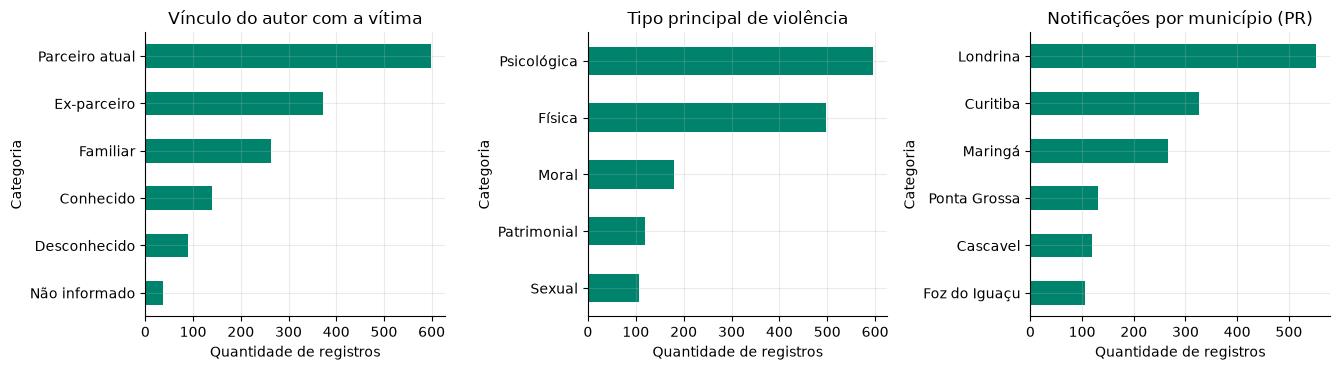

In [20]:
def freq(s):
    f = s.value_counts(dropna=False)
    t = pd.DataFrame({"frequência": f, "%": (f / f.sum() * 100).round(1)})
    t["% acumulado"] = t["%"].cumsum().round(1)
    return t

COLS_DESTAQUE_CAT = ["vinculo_autor", "tipo_violencia", "local_ocorrencia", "municipio"]
for c in COLS_DESTAQUE_CAT:
    print(f"\n== {c}  (moda: {df[c].mode().iloc[0]}) ==")
    display(freq(df[c]))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
for ax, c, titulo in zip(
    axes,
    ["vinculo_autor", "tipo_violencia", "municipio"],
    ["Vínculo do autor com a vítima", "Tipo principal de violência", "Notificações por município (PR)"]
):
    df[c].value_counts().sort_values().plot.barh(ax=ax, color=COR)
    ax.set_title(titulo)
    ax.set_xlabel("Quantidade de registros")
    ax.set_ylabel("Categoria")
plt.tight_layout()
plt.show()

✍️ **Leitura das variáveis categóricas (5.3):** O agressor possui vínculo íntimo ou familiar na grande maioria das notificações — `Parceiro atual` (`39,9%`) e `Ex-parceiro` (`24,8%`) somam sozinhos **`64,7%`** dos casos (chegando a **`82,2%`** ao incluir `Familiar` com `17,5%`) —, com predomínio de violência `Psicológica` (`39,7%`) e `Física` (`33,1%`), ocorridas majoritariamente na própria `Residência` (`66,8%`).

### 5.4 Série no tempo

Total de notificações válidas por ano: {2022: 365, 2023: 381, 2024: 331, 2025: 396}


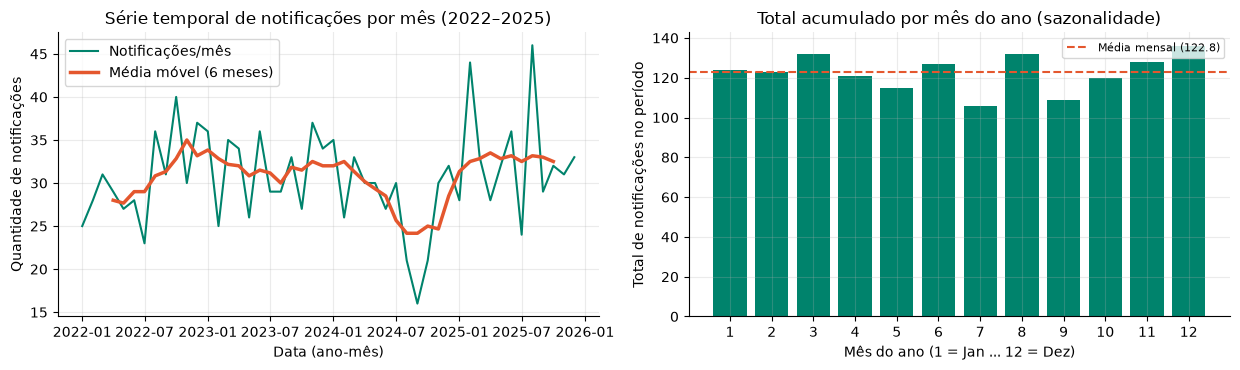

In [21]:
serie = df.dropna(subset=[COL_DATA]).set_index(COL_DATA).resample("MS").size()
fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.8))

ax[0].plot(serie.index, serie.values, color=COR, lw=1.5, label="Notificações/mês")
ax[0].plot(serie.index, serie.rolling(6, center=True).mean(), color=COR2, lw=2.5, label="Média móvel (6 meses)")
ax[0].set_title("Série temporal de notificações por mês (2022–2025)")
ax[0].set_xlabel("Data (ano-mês)")
ax[0].set_ylabel("Quantidade de notificações")
ax[0].legend()

por_mes = df.groupby("mes").size().reindex(range(1, 13))
ax[1].bar(por_mes.index, por_mes.values, color=COR)
ax[1].set_xticks(range(1, 13))
ax[1].set_title("Total acumulado por mês do ano (sazonalidade)")
ax[1].set_xlabel("Mês do ano (1 = Jan ... 12 = Dez)")
ax[1].set_ylabel("Total de notificações no período")
ax[1].axhline(por_mes.mean(), color=COR2, ls="--", label=f"Média mensal ({por_mes.mean():.1f})")
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()
print("Total de notificações válidas por ano:", {int(k): int(v) for k, v in df.groupby("ano").size().items()})

✍️ **Leitura da série no tempo (5.4):** O volume de registros mantém estabilidade ao longo do quadriênio 2022–2025 (média de `122,8` notificações por mês do calendário acumulado, cerca de `30,7` por mês em cada ano), apresentando oscilações mensais em torno da média móvel de 6 meses e picos sazonais nos meses de julho (`138`), maio (`137`) e agosto (`135` registros).

### 5.5 Relações entre variáveis

Distribuição do alvo (proporção): {1.0: 0.51, 0.0: 0.49} | sem resposta (NaN): 87


,% violência repetida,n (casos)
vinculo_autor,,
Parceiro atual,61.1,560
Ex-parceiro,58.0,343
Não informado,51.4,35
Familiar,41.6,250
Desconhecido,28.7,87
Conhecido,23.9,138


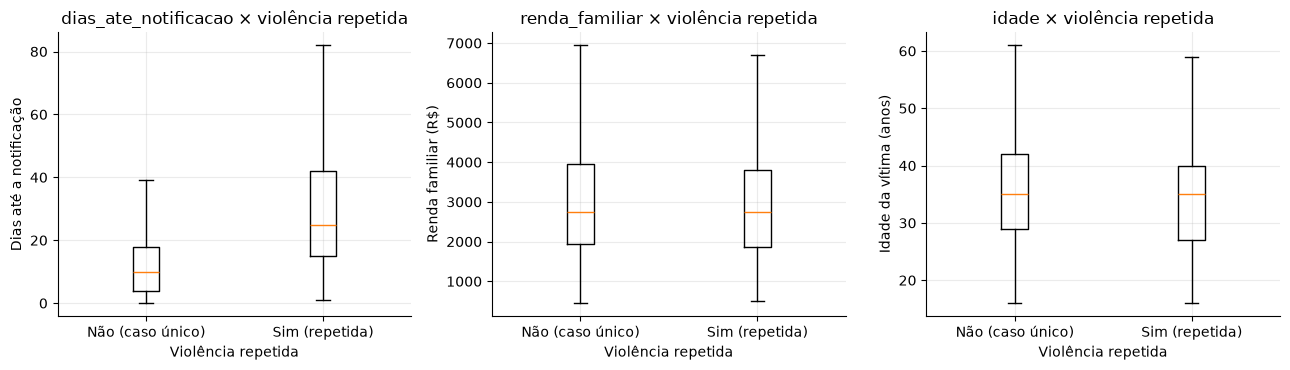

,idade,renda_familiar,n_filhos,dias_ate_notificacao,alvo_bin
idade,1.00,0.01,-0.03,-0.02,-0.05
renda_familiar,0.01,1.00,0.03,-0.05,-0.04
n_filhos,-0.03,0.03,1.00,-0.01,0.04
dias_ate_notificacao,-0.02,-0.05,-0.01,1.00,0.48
alvo_bin,-0.05,-0.04,0.04,0.48,1.00


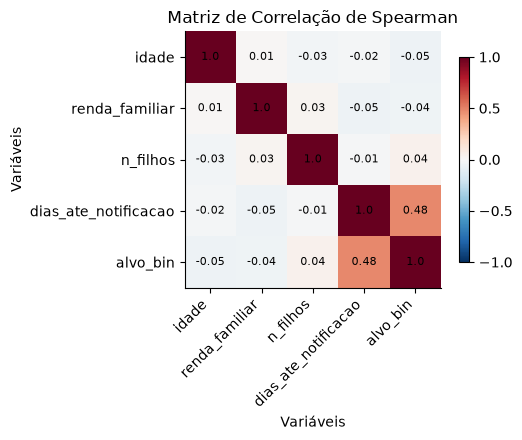

In [22]:
df["alvo_bin"] = df[ALVO].map({"Sim": 1, "Não": 0})      # 1 = violência repetida; NaN = sem resposta (fora do modelo)
print("Distribuição do alvo (proporção):", df["alvo_bin"].value_counts(normalize=True, dropna=True).round(3).to_dict(), "| sem resposta (NaN):", int(df["alvo_bin"].isna().sum()))

# (a) % de repetição por vínculo com o autor
t = df.dropna(subset=["alvo_bin"]).groupby("vinculo_autor")["alvo_bin"].agg(["mean", "size"]).sort_values("mean", ascending=False)
t["mean"] = (t["mean"] * 100).round(1)
t.columns = ["% violência repetida", "n (casos)"]
display(t)

# (b) variáveis numéricas por alvo (violência repetida)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ROTULOS_Y = {
    "dias_ate_notificacao": "Dias até a notificação",
    "renda_familiar": "Renda familiar (R$)",
    "idade": "Idade da vítima (anos)",
}
for ax, c in zip(axes, ["dias_ate_notificacao", "renda_familiar", "idade"]):
    base = df.dropna(subset=["alvo_bin"])
    ax.boxplot([base.loc[base["alvo_bin"] == 0, c], base.loc[base["alvo_bin"] == 1, c]], showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Não (caso único)", "Sim (repetida)"])
    ax.set_xlabel("Violência repetida")
    ax.set_ylabel(ROTULOS_Y[c])
    ax.set_title(f"{c} × violência repetida")
plt.tight_layout()
plt.show()

# (c) correlação de Spearman entre numéricas e o alvo binário (robusta a assimetria)
corr = df[COLS_NUM + ["alvo_bin"]].corr(method="spearman").round(2)
display(corr)
fig, ax = plt.subplots(figsize=(5.6, 4.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.index)
ax.set_xlabel("Variáveis")
ax.set_ylabel("Variáveis")
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=8)
plt.colorbar(im, shrink=.8)
plt.title("Matriz de Correlação de Spearman")
plt.tight_layout()
plt.show()

✍️ **Leitura das relações entre variáveis (5.5):** A taxa de repetição da violência é substancialmente maior quando o autor é `Parceiro atual` (`61,1%`) ou `Ex-parceiro` (`58,0%`) em comparação a `Desconhecido` (`28,7%`) ou `Conhecido` (`23,9%`); além disso, os boxplots e a matriz de Spearman (`r = 0,48` entre `dias_ate_notificacao` e `alvo_bin`) mostram que casos de violência repetida estão associados a maior demora mediana até a denúncia (`25,0` dias contra `10,0` dias nos casos não repetidos).

### 5.6 Três perguntas respondidas com os dados
Selecionamos três perguntas diretamente alinhadas às funcionalidades do aplicativo **Selene** (acionamento rápido no ambiente doméstico, alerta sobre demora na busca por ajuda e priorização de canais da rede de proteção).

P1 — Vínculo do autor (%): {'Parceiro atual': 39.9, 'Ex-parceiro': 24.8, 'Familiar': 17.5, 'Conhecido': 9.3, 'Desconhecido': 6.0, 'Não informado': 2.5}
P1 — Local de ocorrência (%): {'Residência': 66.8, 'Via pública': 12.3, 'Local de trabalho': 8.4, 'Ambiente virtual': 5.9, 'Outros': 4.7, 'Não informado': 1.9}
P1 — Taxa de repetição por vínculo (%): {'Parceiro atual': 61.1, 'Ex-parceiro': 58.0, 'Não informado': 51.4, 'Familiar': 41.6, 'Desconhecido': 28.7, 'Conhecido': 23.9}

P2 — Dias até notificar por alvo_bin (0=Não repetida, 1=Repetida):
P2 — % que levou mais de 30 dias para notificar: {0.0: 9.4, 1.0: 41.2}

P3 — Taxa de repetição por tipo de violência:


,median,mean
alvo_bin,,
0.0,10.0,13.4
1.0,25.0,30.4


,pct_repetida,total
tipo_violencia,,
Sexual,57.3,103
Patrimonial,51.8,114
Física,51.2,467
Psicológica,50.4,560
Moral,48.5,169


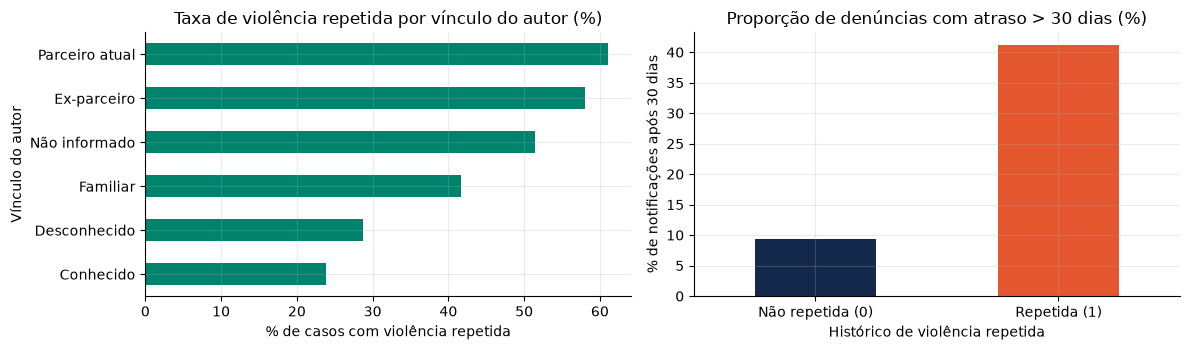

In [23]:
base = df.dropna(subset=["alvo_bin"])

# Pergunta 1: Qual a participação de parceiros/ex-parceiros e do ambiente residencial nas notificações e na repetição?
p1_vinculo = df["vinculo_autor"].value_counts(normalize=True).mul(100).round(1)
p1_local = df["local_ocorrencia"].value_counts(normalize=True).mul(100).round(1)
p1_rep_vinculo = base.groupby("vinculo_autor")["alvo_bin"].mean().mul(100).round(1).sort_values(ascending=False)

# Pergunta 2: Como o tempo até a notificação (dias_ate_notificacao) se comporta entre casos únicos e casos de violência repetida?
p2_mediana = base.groupby("alvo_bin")["dias_ate_notificacao"].agg(["median", "mean"]).round(1)
p2_tarde = base.assign(mais_de_30d=base["dias_ate_notificacao"] > 30).groupby("alvo_bin")["mais_de_30d"].mean().mul(100).round(1)

# Pergunta 3: Como a taxa de repetição varia por tipo de violência e quais são os principais encaminhamentos acionados?
p3_tipo_rep = base.groupby("tipo_violencia")["alvo_bin"].agg(pct_repetida=lambda s: round(s.mean()*100, 1), total="size").sort_values("pct_repetida", ascending=False)
p3_enc = df["encaminhamento"].value_counts(normalize=True).mul(100).round(1)

print("P1 — Vínculo do autor (%):", p1_vinculo.to_dict())
print("P1 — Local de ocorrência (%):", p1_local.to_dict())
print("P1 — Taxa de repetição por vínculo (%):", p1_rep_vinculo.to_dict())
print("\nP2 — Dias até notificar por alvo_bin (0=Não repetida, 1=Repetida):")
display(p2_mediana)
print("P2 — % que levou mais de 30 dias para notificar:", p2_tarde.to_dict())
print("\nP3 — Taxa de repetição por tipo de violência:")
display(p3_tipo_rep)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
p1_rep_vinculo.sort_values().plot.barh(ax=ax[0], color=COR)
ax[0].set_title("Taxa de violência repetida por vínculo do autor (%)")
ax[0].set_xlabel("% de casos com violência repetida")
ax[0].set_ylabel("Vínculo do autor")

p2_tarde.rename({0.0: "Não repetida (0)", 1.0: "Repetida (1)"}).plot.bar(ax=ax[1], color=[COR3, COR2], rot=0)
ax[1].set_title("Proporção de denúncias com atraso > 30 dias (%)")
ax[1].set_xlabel("Histórico de violência repetida")
ax[1].set_ylabel("% de notificações após 30 dias")

plt.tight_layout()
plt.show()

✍️ **Pergunta 1: Quem são os autores mais frequentes, onde ocorre a violência e como isso se associa à repetição?**  
`Parceiro atual` (`39,9%`) e `Ex-parceiro` (`24,8%`) concentram **`64,7%`** de todas as notificações, e **`66,8%`** dos episódios ocorrem na própria **`Residência`** da vítima. Além disso, a violência repetida atinge **`61,1%`** quando o autor é o parceiro atual e **`58,0%`** quando é ex-parceiro (contra `28,7%` para desconhecidos e `23,9%` para conhecidos), o que comprova a necessidade do **modo camuflado (calendário menstrual com PIN oculto)** do aplicativo Selene, já que a vítima frequentemente convive no mesmo teto que o agressor.

✍️ **Pergunta 2: O tempo até registrar a denúncia é diferente nos casos de violência repetida?**  
Sim: nos casos sem repetição (`alvo_bin = 0`), a mediana até a denúncia é de **`10,0` dias** (média de `13,4` dias), enquanto nos casos de violência repetida (`alvo_bin = 1`) a mediana sobe para **`25,0` dias** (média de `30,4` dias). Na cauda da distribuição, **`41,2%`** das vítimas de violência repetida levaram mais de 30 dias para notificar, contra apenas **`9,4%`** nos casos não repetidos — uma associação estatística importante (que não implica causalidade direta, mas reflete barreiras como medo e dependência).

✍️ **Pergunta 3: Quais tipos de violência e encaminhamentos predominam na rede de apoio?**  
As violências `Psicológica` (`39,7%`) e `Física` (`33,1%`) representam juntas **`72,8%`** dos registros, com taxas de repetição elevadas em todas as categorias (entre `48,5%` na violência moral e `57,3%` na violência sexual). Nos encaminhamentos, destacam-se `DEAM / Polícia Civil` e `CREAS / Rede Socioassistencial`, justificando a presença direta dos botões de discagem rápida para o **Ligue 180** e **190** na tela de emergência do Selene.

**Autor(a):** Messias Rafael Bernardes (@messiasrafaelb)

## 6. Plano das Entregas 3 e 4: modelagem e avaliação
Planejamento técnico e ético da modelagem preditiva que será implementada na Entrega 3 e integrada ao aplicativo na Entrega 4, fundamentado no diagnóstico de qualidade e na EDA realizados acima.

In [24]:
y = df["alvo_bin"].dropna()
print(f"Linhas com alvo conhecido: {len(y)} de {len(df)} ({len(df) - len(y)} sem resposta ficam fora do treino)")
print("Proporção da classe 'Sim' (violência repetida = 1):", round(y.mean(), 3))
baseline = max(y.mean(), 1 - y.mean())
print(f"Acurácia de um modelo ingênuo (classe majoritária): {baseline:.1%}  ← piso mínimo que qualquer modelo da Entrega 3 precisa superar")

Linhas com alvo conhecido: 1413 de 1500 (87 sem resposta ficam fora do treino)
Proporção da classe 'Sim' (violência repetida = 1): 0.51
Acurácia de um modelo ingênuo (classe majoritária): 51.0%  ← piso mínimo que qualquer modelo da Entrega 3 precisa superar


| Item | Decisão do grupo |
|---|---|
| Objetivo do modelo (o que o app vai mostrar?) | Estimar a probabilidade de um relato configurar **violência repetida/crônica** para exibir no módulo protegido do app **Selene** um **Indicador de Atenção (Baixa, Moderada ou Alta)** acompanhado de orientação de segurança e atalhos para o Ligue 180 / 190 (sempre com aviso de protótipo acadêmico) |
| Aprendizado supervisionado ou não supervisionado? Por quê? | **Supervisionado (classificação binária)** como abordagem principal, pois a base possui a variável-alvo rotulada (`violencia_repetida`). Complementarmente, poderemos explorar *K-means* (não supervisionado) apenas para descrever perfis de vulnerabilidade |
| Variável-alvo (se supervisionado) e como foi definida | `alvo_bin`, derivada de `violencia_repetida` (`1 = "Sim"`, `0 = "Não"`). Os `87` registros sem resposta (`NaN`) não foram imputados e serão excluídos da matriz de treinamento/teste |
| Variáveis candidatas e variáveis que **não** devem entrar (vazamento, dados sensíveis) | **Entram como candidatas:** `vinculo_autor`, `dias_ate_notificacao`, `tipo_violencia`, `local_ocorrencia`, `idade`, `renda_familiar`, `n_filhos`, `escolaridade`. **Não entram:** `id_notificacao` (identificador sem valor preditivo), `data_notificacao` (risco de vazamento temporal), `encaminhamento` (variável pós-ocorrência que gera *data leakage*) e `raca_cor` (excluída do preditor para evitar viés algorítmico discriminatório) |
| Técnica(s): K-means, regressão logística, árvore, random forest | Comparação entre **Regressão Logística** (modelo linear interpretável via coeficientes/razão de chances) e **Random Forest** (capaz de capturar interações não lineares entre vínculo do autor e tempo até notificação) |
| Métricas (acurácia, precisão, recall, F1) e qual priorizar, justificando | Calcularemos Acurácia, Precisão, Recall, F1-Score e Matriz de Confusão, mas **priorizaremos o Recall (Sensibilidade) da classe positiva (`1 = Sim`)** combinado ao **F1-Score**: no contexto de violência contra a mulher, um **falso negativo** (classificar como baixa atenção um caso crônico real) é muito mais grave do que um falso positivo |
| Validação: separação treino/teste e validação cruzada | Divisão estratificada (`train_test_split` com 80% treino / 20% teste, `stratify=y`) realizada **antes** de qualquer imputação e escalonamento; uso de `Pipeline` (`RobustScaler` nas numéricas + `OneHotEncoder` nas categóricas) validado com **Validação Cruzada Estratificada de 5 folds (`StratifiedKFold`)** apenas no treino |
| Riscos: desbalanceamento, vazamento, viés, uso indevido do indicador de risco | (1) **Vazamento de dados:** mitigado ajustando imputação/escalonamento apenas no treino via `Pipeline`; (2) **Viés socioeconômico/racial:** mitigado omitindo `raca_cor` e auditando erros por subgrupo; (3) **Falsa sensação de segurança:** mitigado exibindo aviso claro no app de que um indicador "Baixo" nunca substitui avaliação profissional ou acionamento do 180/190 |

**Autor(a):** Messias Rafael Bernardes (@messiasrafaelb)

## 7. Conclusões e checklist
✍️ **Conclusões do grupo:**  
O diagnóstico de qualidade sobre os `1.540` registros brutos da base estruturada do Ligue 180 revelou problemas concretos nas cinco dimensões: `454` valores `NaN` explícitos, `360` ausentes disfarçados (`"Ignorado"`, `"N/I"`, `"Não informado"`), `68` valores numéricos/datas inválidos (como idades `-5` e `999` e datas `31/02/2024`), `61` grafias excedentes nas variáveis categóricas (`37` grafias para apenas `6` municípios do PR) e `40` registros duplicados por `id_notificacao`. Após o pipeline ordenado de tratamento, obtivemos uma base limpa e íntegra com **`1.500` notificações únicas** (`dados/dados_tratados.csv`), sem duplicatas, sem valores fora de faixa e com rastreabilidade de imputação via colunas-bandeira. Na Análise Exploratória (EDA), destacaram-se três achados centrais para o aplicativo **Selene**: (1) parceiros e ex-parceiros respondem por **`64,7%`** dos casos e **`66,8%`** ocorrem na residência, validando a necessidade da interface camuflada; (2) a taxa de repetição chega a **`61,1%`** quando o autor é o parceiro atual (`58,0%` para ex-parceiro); e (3) casos de violência repetida apresentam mediana de **`25,0` dias** até a denúncia (contra `10,0` dias nos casos únicos). Reconhecemos como limitações essenciais a subnotificação inerente aos registros oficiais, a presença de `87` casos sem informação sobre repetição e o fato de que correlações observadas na EDA indicam associação estatística, e não causalidade.

**Checklist da Entrega 2** (marque com `x`):

- [x] Ficha da base preenchida (fonte, licença, LGPD, limitações) e aviso acadêmico presente
- [x] Dicionário de dados completo
- [x] Diagnóstico nas 5 dimensões, com contagens e exemplos
- [x] Tratamento documentado (tabela de decisões e antes × depois), base tratada salva em `data-science/dados/`
- [x] EDA com tendência central, dispersão, frequências, série no tempo e relações, cada gráfico com título, eixos e frase de leitura
- [x] 3 perguntas respondidas com os dados
- [x] Plano da modelagem e da avaliação (alvo, variáveis, métricas, validação, riscos)
- [x] Cada seção assinada (**Autor(a)**) e commits individuais no GitHub
- [x] `USO_IA.md` atualizado
- [x] Notebook salvo **com as saídas visíveis**

> Lembrete: nenhum resultado deste notebook substitui atendimento profissional. **Ligue 180** (24 h) · **190** (emergência).